<a href="https://colab.research.google.com/github/nazwahummaimah/-/blob/master/PM_P9_Nazwa_Hummaimah_Shiddqin_2488010039.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 — Menyiapkan data & scaling (wajib).

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'usia': [19, 22, 25, 28, 35, 40, 45, 48, 52, 55],
    'pendapatan': [
        3000000, 3500000, 4000000, 4500000, 5000000,
        7000000, 7500000, 8000000, 9000000, 10000000
    ],
    'skor_belanja': [85, 80, 78, 75, 60, 55, 45, 40, 30, 25]
})

print(df)

   usia  pendapatan  skor_belanja
0    19     3000000            85
1    22     3500000            80
2    25     4000000            78
3    28     4500000            75
4    35     5000000            60
5    40     7000000            55
6    45     7500000            45
7    48     8000000            40
8    52     9000000            30
9    55    10000000            25


In [15]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(df)

Langkah 2 — Metode Elbow menentukan K.

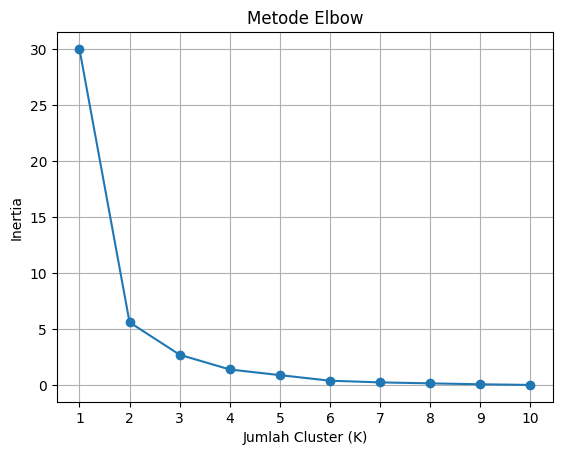

In [17]:

from sklearn.cluster import KMeans

inertias = []

for k in range(1, 11):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.title('Metode Elbow')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Langkah 3 — Menjalankan K-Means (K=3).

In [18]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X_scaled)

print(df['cluster'].value_counts())



cluster
1    4
2    3
0    3
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [19]:
from sklearn.metrics import silhouette_score

score3 = silhouette_score(X_scaled, df['cluster'])

print("Silhouette Score K=3:", round(score3, 3))


Silhouette Score K=3: 0.488


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [21]:
profil = df.groupby('cluster')[
    ['usia', 'pendapatan', 'skor_belanja']
].mean().round(1)

print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        51.7   9000000.0          31.7
1        23.5   3750000.0          79.5
2        40.0   6500000.0          53.3


D. Latihan Mandiri


6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [22]:
kmeans5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

cluster5 = kmeans5.fit_predict(X_scaled)
score5 = silhouette_score(X_scaled, cluster5)

print("Silhouette K=3:", round(score3, 3))
print("Silhouette K=5:", round(score5, 3))

Silhouette K=3: 0.488
Silhouette K=5: 0.392


7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?


In [23]:
X = df[['usia', 'pendapatan', 'skor_belanja']]

kmeans_raw = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_raw = kmeans_raw.fit_predict(X)
score_raw = silhouette_score(X, cluster_raw)

print("Silhouette dengan scaling:", round(score3, 3))
print("Silhouette tanpa scaling:", round(score_raw, 3))

Silhouette dengan scaling: 0.488
Silhouette tanpa scaling: 0.638


8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).


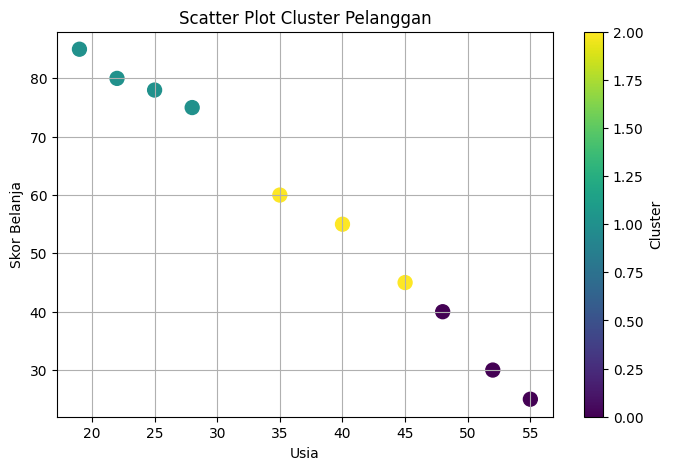

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=df['cluster'],
    cmap='viridis',
    s=100
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster Pelanggan')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

E. Refleksi

9. Bagaimana K-Means menemukan kelompok tanpa label?


K-Means menemukan kelompok tanpa label dengan cara melihat kemiripan jarak antar data. Algoritma ini menentukan jumlah cluster (K), lalu memilih titik pusat awal yang disebut centroid secara acak. Setiap data kemudian dikelompokkan ke cluster yang memiliki centroid terdekat. Posisi centroid selanjutnya dihitung ulang berdasarkan rata-rata data dalam setiap cluster. Proses ini terus dilakukan sampai posisi centroid stabil. Dengan cara tersebut, K-Means dapat menemukan pola dan mengelompokkan data berdasarkan kemiripan karakteristiknya tanpa harus memiliki label atau kategori yang sudah ditentukan sebelumnya.

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?


Metode Elbow menunjukkan siku di K=3 karena penurunan nilai inertia dari K=1 hingga K=3 cukup besar, sedangkan setelah K=3 penurunannya mulai melambat. Hal ini menunjukkan bahwa penambahan jumlah cluster setelah tiga kelompok tidak memberikan perubahan yang terlalu besar pada hasil pengelompokan. Oleh karena itu, K=3 dapat dipilih karena sudah cukup untuk mengelompokkan data berdasarkan kemiripan karakteristiknya. Metode Elbow membantu menentukan jumlah cluster yang sesuai agar pengelompokan data lebih efektif dan tidak perlu menambah kelompok jika hasilnya tidak memberikan peningkatan yang berarti.

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Scaling penting dalam K-Means karena setiap fitur memiliki rentang nilai yang berbeda, misalnya usia berkisar puluhan, skor belanja berkisar 0–100, sedangkan pendapatan bisa mencapai jutaan rupiah. K-Means menggunakan jarak untuk menentukan kelompok data, sehingga fitur dengan nilai besar seperti pendapatan dapat lebih mendominasi perhitungan. Dengan scaling, skala setiap fitur menjadi lebih sebanding sehingga usia, pendapatan, dan skor belanja dapat dipertimbangkan dalam proses pengelompokan. Jika scaling tidak dilakukan, hasil cluster bisa lebih banyak dipengaruhi oleh pendapatan dan kurang menggambarkan kemiripan karakteristik pelanggan secara keseluruhan.